# Assignment No. 08 - Bayesian Network for Heart Disease Diagnosis

Construct a Bayesian Network using the Cleveland Heart Disease dataset and perform probabilistic inference.

In [1]:
!pip install -q pgmpy pandas numpy networkx matplotlib

In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

C:\Users\ACER\anaconda3\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
# Load heart.csv
heartDisease = pd.read_csv('heart.csv')
heartDisease = heartDisease.replace('?', np.nan)

# Display the data
print('Few examples from the dataset are given below:')
display(heartDisease.head())
print('\nDataset shape:', heartDisease.shape)

Few examples from the dataset are given below:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Dataset shape: (303, 14)


In [4]:
# Clean data
heartDisease = heartDisease.apply(pd.to_numeric, errors='coerce')
heartDisease = heartDisease.dropna()

print('Dataset after cleaning:')
display(heartDisease.head())
print('\nDataset shape after cleaning:', heartDisease.shape)

Dataset after cleaning:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Dataset shape after cleaning: (297, 14)


In [5]:
# Bayesian Network Model
model = DiscreteBayesianNetwork([
    ('age', 'trestbps'),
    ('age', 'fbs'),
    ('sex', 'trestbps'),
    ('exang', 'trestbps'),
    ('trestbps', 'heartdisease'),
    ('fbs', 'heartdisease'),
    ('heartdisease', 'restecg'),
    ('heartdisease', 'thalach'),
    ('heartdisease', 'chol')
])

print('Bayesian Network Structure:')
print(list(model.edges()))

Bayesian Network Structure:
[('age', 'trestbps'), ('age', 'fbs'), ('trestbps', 'heartdisease'), ('fbs', 'heartdisease'), ('sex', 'trestbps'), ('exang', 'trestbps'), ('heartdisease', 'restecg'), ('heartdisease', 'thalach'), ('heartdisease', 'chol')]


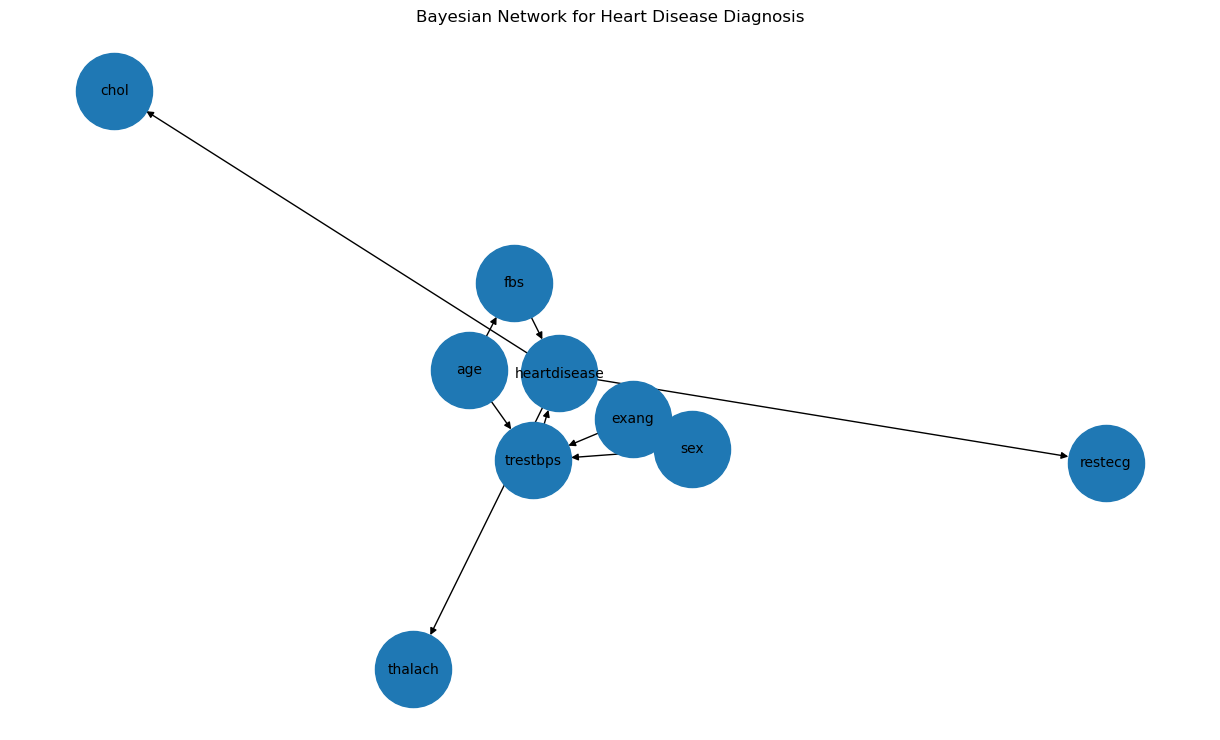

In [6]:
# Visualize Bayesian Network
plt.figure(figsize=(12, 7))
G = nx.DiGraph()
G.add_edges_from(model.edges())
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=3000, font_size=10, arrows=True)
plt.title('Bayesian Network for Heart Disease Diagnosis')
plt.show()

In [7]:
# Learn CPDs using Maximum Likelihood Estimator

print("Learning CPDs using Maximum Likelihood Estimator...")

estimator = MaximumLikelihoodEstimator(model, heartDisease)

# Estimate CPDs
cpds = estimator.get_parameters()

# Add CPDs to the model
model.add_cpds(*cpds)

print("CPDs learned successfully.")

Learning CPDs using Maximum Likelihood Estimator...
CPDs learned successfully.


C:\Users\ACER\AppData\Local\Temp\ipykernel_3180\3756387957.py:5: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = MaximumLikelihoodEstimator(model, heartDisease)


In [8]:
# Display CPDs
for cpd in model.get_cpds():
    print('\n', cpd)


 +-----------+------------+
| age(29.0) | 0.003367   |
+-----------+------------+
| age(34.0) | 0.00673401 |
+-----------+------------+
| age(35.0) | 0.013468   |
+-----------+------------+
| age(37.0) | 0.00673401 |
+-----------+------------+
| age(38.0) | 0.003367   |
+-----------+------------+
| age(39.0) | 0.013468   |
+-----------+------------+
| age(40.0) | 0.010101   |
+-----------+------------+
| age(41.0) | 0.03367    |
+-----------+------------+
| age(42.0) | 0.026936   |
+-----------+------------+
| age(43.0) | 0.023569   |
+-----------+------------+
| age(44.0) | 0.037037   |
+-----------+------------+
| age(45.0) | 0.026936   |
+-----------+------------+
| age(46.0) | 0.023569   |
+-----------+------------+
| age(47.0) | 0.016835   |
+-----------+------------+
| age(48.0) | 0.023569   |
+-----------+------------+
| age(49.0) | 0.016835   |
+-----------+------------+
| age(50.0) | 0.023569   |
+-----------+------------+
| age(51.0) | 0.040404   |
+-----------+------------+

In [9]:
# Bayesian Inference
heartDisease_infer = VariableElimination(model)
print('Inferencing with Bayesian Network:')

Inferencing with Bayesian Network:


In [10]:
# Probability of Heart Disease given Age = 29

print("\n1. Probability of Heart Disease given Age = 29")

q = heartDisease_infer.query(
    variables=["heartdisease"],
    evidence={"age": 29.0}
)

print(q)


1. Probability of Heart Disease given Age = 29
+-----------------+---------------------+
| heartdisease    |   phi(heartdisease) |
+=================+=====================+
| heartdisease(0) |              0.5846 |
+-----------------+---------------------+
| heartdisease(1) |              0.1820 |
+-----------------+---------------------+
| heartdisease(2) |              0.1006 |
+-----------------+---------------------+
| heartdisease(3) |              0.0799 |
+-----------------+---------------------+
| heartdisease(4) |              0.0530 |
+-----------------+---------------------+


In [11]:
chol_value = heartDisease["chol"].iloc[0]

print(f"\n2. Probability of Heart Disease given Cholesterol = {chol_value}")

q = heartDisease_infer.query(
    variables=["heartdisease"],
    evidence={"chol": chol_value}
)

print(q)


2. Probability of Heart Disease given Cholesterol = 233.0
+-----------------+---------------------+
| heartdisease    |   phi(heartdisease) |
+=================+=====================+
| heartdisease(0) |              0.7350 |
+-----------------+---------------------+
| heartdisease(1) |              0.2650 |
+-----------------+---------------------+
| heartdisease(2) |              0.0000 |
+-----------------+---------------------+
| heartdisease(3) |              0.0000 |
+-----------------+---------------------+
| heartdisease(4) |              0.0000 |
+-----------------+---------------------+


In [12]:
# Probability using multiple patient attributes
print('\n3. Probability of Heart Disease given multiple attributes')
q = heartDisease_infer.query(
    variables=['heartdisease'],
    evidence={
        'age': 63,
        'sex': 1,
        'fbs': 1,
        'exang': 0
    }
)
print(q)


3. Probability of Heart Disease given multiple attributes
+-----------------+---------------------+
| heartdisease    |   phi(heartdisease) |
+=================+=====================+
| heartdisease(0) |              0.6667 |
+-----------------+---------------------+
| heartdisease(1) |              0.0000 |
+-----------------+---------------------+
| heartdisease(2) |              0.1667 |
+-----------------+---------------------+
| heartdisease(3) |              0.1667 |
+-----------------+---------------------+
| heartdisease(4) |              0.0000 |
+-----------------+---------------------+


In [13]:
# Most probable diagnosis
probabilities = q.values
states = q.state_names['heartdisease']
most_probable_state = states[np.argmax(probabilities)]
highest_probability = np.max(probabilities)

print('Most probable Heart Disease category:', most_probable_state)
print('Probability:', round(float(highest_probability), 4))

Most probable Heart Disease category: 0
Probability: 0.6667


In [14]:
print('''
CONCLUSION:
A Bayesian Network was successfully constructed using the Cleveland
Heart Disease dataset. Conditional Probability Distributions (CPDs)
were learned using the Maximum Likelihood Estimator.

Bayesian inference was performed to estimate the probability of heart
disease based on patient attributes. Thus, the Bayesian Network
demonstrates probabilistic diagnosis using medical data.
''')


CONCLUSION:
A Bayesian Network was successfully constructed using the Cleveland
Heart Disease dataset. Conditional Probability Distributions (CPDs)
were learned using the Maximum Likelihood Estimator.

Bayesian inference was performed to estimate the probability of heart
disease based on patient attributes. Thus, the Bayesian Network
demonstrates probabilistic diagnosis using medical data.

